# CIFAR-10 with deep learning: transfer learning and fine-tuning


---
## 1. Problem Specification

### 1.1 Learning Type
This is a supervised multi-class image classification problem. Given a 32×32 colour image as input, the model must predict one of 10 mutually exclusive object categories. The labels are provided in the dataset, making this a supervised learning task.

### 1.2 Dataset
CIFAR-10 60,000 colour images (32×32×3) across 10 classes:  airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck  
- Training set: 50,000 images (5,000 per class)  
- Test set: 10,000 images (1,000 per class)

### 1.3 Deep Learning Architectures
We evaluate three pre-trained CNN architectures to identify the best-performing model:

1. ResNet-18: 11.7M parameters. 
2. ResNet-50: 25.6M parameters. 
3. EfficientNet-B0: 5.3M parameters.

All models are pre-trained on ImageNet-1K (1.28M images, 1,000 classes). ImageNet does not contain CIFAR-10 images. We fine-tune the final classification layer for 10-class output.

### 1.4 Framework
PyTorch (with torchvision for pre-trained model weights).

### 1.5 Methodology
We train all three models on a stratified training sample with frozen convolutional layers for 10 epochs. Then, we compare accuracy, precision, recall, and F1-score on a held-out validation set and the official test set.

### 1.6 Data Partitioning
From the 50,000 training images, we draw a stratified sample of 10,000 images (1,000 per class), then split into:
- Training set: 8,000 images (800 per class) for model training
- Validation set: 2,000 images (200 per class) for hyperparameter monitoring and early stopping
- Test set: 10,000 images (official CIFAR-10 test split) for final evaluation only

This ensures proper train/validation/test separation, preventing data leakage and enabling unbiased performance estimation.

---
## 2. Environment Setup and Imports

In [4]:
%pip install torch torchvision torchaudio

Note: you may need to restart the kernel to use updated packages.


In [5]:
# Core libraries
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models

# Data handling
import numpy as np
import pandas as pd
import copy
import time
import warnings
warnings.filterwarnings('ignore')

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Evaluation
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
from sklearn.model_selection import StratifiedShuffleSplit

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

print(f"PyTorch version: {torch.__version__}")
print(f"Torchvision version: {torchvision.__version__}")

PyTorch version: 2.12.0+cpu
Torchvision version: 0.27.0+cpu


### 2.1 Device Configuration

In [7]:
if torch.cuda.is_available():
    device = torch.device('cuda')
    print(f"Using CUDA GPU: {torch.cuda.get_device_name(0)}")
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Using Apple Silicon MPS")
else:
    device = torch.device('cpu')
    print("Using CPU")

print(f"Device: {device}")

Using CPU
Device: cpu


---
## 3. Data Loading and Pre-processing

### 3.1 Data Transformation
Since we fine-tune models pre-trained on ImageNet, we apply:
- Resize to 224×224: Standard input size for ImageNet-based architectures
- Data Augmentation (training only): Random horizontal flips, slight rotation, and colour jitter to reduce overfitting and improve generalization
- Normalisation: ImageNet channel means and standard deviations to match the pre-training distribution

In [9]:
CLASSES = ('airplane', 'automobile', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')
NUM_CLASSES = 10

# Training transforms — with augmentation
train_transform = transforms.Compose([
    transforms.Resize(224),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Validation/test transforms — no augmentation
eval_transform = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

print("Transforms defined successfully.")

Transforms defined successfully.


### 3.2 Load CIFAR-10 Dataset

In [11]:
# Load with training transforms (for training split)
train_dataset_aug = torchvision.datasets.CIFAR10(
    root='./data', train=True, download=True, transform=train_transform
)

# Load same data with eval transforms (for validation split — no augmentation)
train_dataset_eval = torchvision.datasets.CIFAR10(
    root='./data', train=True, download=False, transform=eval_transform
)

# Test set
test_dataset = torchvision.datasets.CIFAR10(
    root='./data', train=False, download=True, transform=eval_transform
)

print(f"Full training set: {len(train_dataset_aug)} images")
print(f"Test set: {len(test_dataset)} images")
print(f"Image shape (after transform): {train_dataset_aug[0][0].shape}")
print(f"Number of classes: {NUM_CLASSES}")

100%|██████████| 170M/170M [00:58<00:00, 2.91MB/s] 


Full training set: 50000 images
Test set: 10000 images
Image shape (after transform): torch.Size([3, 224, 224])
Number of classes: 10


### 3.3 Exploratory Data Visualisation

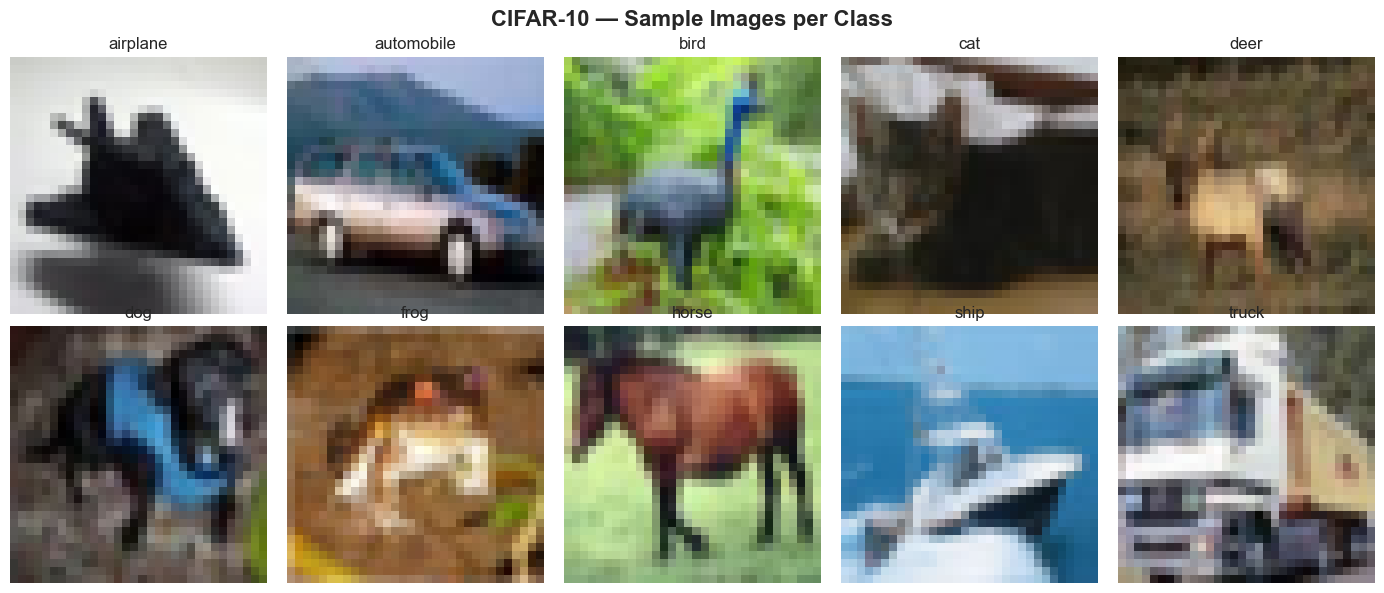

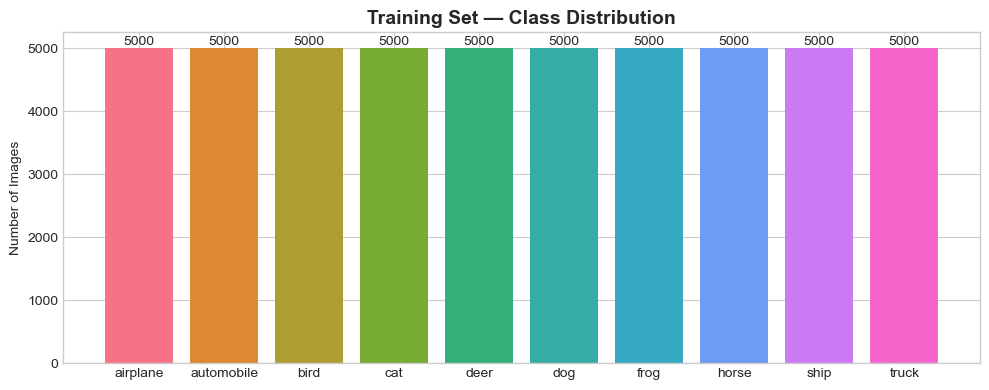

Dataset is balanced: 5,000 images per class.


In [13]:
# Raw dataset for visualisation
raw_dataset = torchvision.datasets.CIFAR10(
    root='./data', train=True, download=False, transform=transforms.ToTensor()
)

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
fig.suptitle('CIFAR-10 — Sample Images per Class', fontsize=16, fontweight='bold')

for class_idx in range(NUM_CLASSES):
    row, col = class_idx // 5, class_idx % 5
    for img, label in raw_dataset:
        if label == class_idx:
            axes[row, col].imshow(img.permute(1, 2, 0).numpy())
            axes[row, col].set_title(CLASSES[class_idx], fontsize=12)
            axes[row, col].axis('off')
            break

plt.tight_layout()
plt.show()

# Class distribution
train_labels = np.array(train_dataset_aug.targets)
unique, counts = np.unique(train_labels, return_counts=True)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(CLASSES, counts, color=sns.color_palette("husl", NUM_CLASSES))
ax.set_title('Training Set — Class Distribution', fontsize=14, fontweight='bold')
ax.set_ylabel('Number of Images')
for i, v in enumerate(counts):
    ax.text(i, v + 50, str(v), ha='center', fontsize=10)
plt.tight_layout()
plt.show()

print("Dataset is balanced: 5,000 images per class.")

---
## 4. Data Partitioning: Train / Validation / Test Split

We create a stratified sample of 10,000 images (1,000 per class), then split it into:
- Training: 8,000 images (800 per class) used for gradient updates
- Validation: 2,000 images (200 per class) used for monitoring overfitting and early stopping
- Test: 10,000 images (official split) used only for final evaluation

The validation set uses no data augmentation to provide an unbiased estimate of generalisation performance.

In [15]:
train_labels = np.array(train_dataset_aug.targets)

# Step 1: Draw stratified 10,000-image sample
sss = StratifiedShuffleSplit(n_splits=1, train_size=10000, random_state=SEED)
sample_indices, _ = next(sss.split(np.zeros(len(train_labels)), train_labels))

# Step 2: Split the 10k sample into 8k train + 2k validation
sample_labels = train_labels[sample_indices]
sss2 = StratifiedShuffleSplit(n_splits=1, train_size=8000, test_size=2000, random_state=SEED)
train_idx_local, val_idx_local = next(sss2.split(np.zeros(len(sample_labels)), sample_labels))

train_indices = sample_indices[train_idx_local]  # 8,000 images
val_indices = sample_indices[val_idx_local]       # 2,000 images

# Training set uses augmented transforms
train_subset = Subset(train_dataset_aug, train_indices)

# Validation set uses eval transforms (NO augmentation)
val_subset = Subset(train_dataset_eval, val_indices)

# Verify stratification
train_split_labels = train_labels[train_indices]
val_split_labels = train_labels[val_indices]

print("Data Partitioning Summary:")
print(f"{'':>12s}  {'Train':>6s}  {'Val':>6s}")
print(f"{'─'*30}")
for i, cls in enumerate(CLASSES):
    t_count = np.sum(train_split_labels == i)
    v_count = np.sum(val_split_labels == i)
    print(f"{cls:>12s}  {t_count:>6d}  {v_count:>6d}")
print(f"{'─'*30}")
print(f"{'TOTAL':>12s}  {len(train_indices):>6d}  {len(val_indices):>6d}")

# DataLoaders
BATCH_SIZE = 64
train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=0, pin_memory=True)
val_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=0, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=0, pin_memory=True)

print(f"\nTrain batches: {len(train_loader)} | Val batches: {len(val_loader)} | Test batches: {len(test_loader)}")

Data Partitioning Summary:
               Train     Val
──────────────────────────────
    airplane     800     200
  automobile     800     200
        bird     800     200
         cat     800     200
        deer     800     200
         dog     800     200
        frog     800     200
       horse     800     200
        ship     800     200
       truck     800     200
──────────────────────────────
       TOTAL    8000    2000

Train batches: 125 | Val batches: 32 | Test batches: 157


---
## 5. Model Definitions

All three models use ImageNet-1K pre-trained weights. We replace the final classification layer for 10-class output.

Pre-trained model constraint: None of these models were pre-trained on CIFAR-10. ImageNet-1K is a completely separate dataset (1,000 classes, 1.28M images at 224×224 resolution).

In [17]:
def create_model(model_name, num_classes=10, freeze_features=True):
    """
    Create a pre-trained model with a modified final classification layer.
    
    Parameters:
        model_name (str): 'resnet18', 'resnet50', or 'efficientnet_b0'
        num_classes (int): Number of output classes
        freeze_features (bool): If True, freeze all layers except the classifier
    
    Returns:
        model: PyTorch model moved to the active device
    """
    if model_name == 'resnet18':
        model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        if freeze_features:
            for param in model.parameters():
                param.requires_grad = False
        num_features = model.fc.in_features
        model.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(num_features, num_classes))
        
    elif model_name == 'resnet50':
        model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
        if freeze_features:
            for param in model.parameters():
                param.requires_grad = False
        num_features = model.fc.in_features
        model.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(num_features, num_classes))
        
    elif model_name == 'efficientnet_b0':
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        if freeze_features:
            for param in model.parameters():
                param.requires_grad = False
        num_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(num_features, num_classes))
    else:
        raise ValueError(f"Unknown model: {model_name}")
    
    model = model.to(device)
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{model_name} — Total: {total:,} | Trainable: {trainable:,} ({100*trainable/total:.1f}%)")
    return model

print("=" * 70)
print("Model Architecture Summary (Frozen Features)")
print("=" * 70)
for name in ['resnet18', 'resnet50', 'efficientnet_b0']:
    _ = create_model(name, freeze_features=True)
print()

Model Architecture Summary (Frozen Features)
resnet18 — Total: 11,181,642 | Trainable: 5,130 (0.0%)
resnet50 — Total: 23,528,522 | Trainable: 20,490 (0.1%)
efficientnet_b0 — Total: 4,020,358 | Trainable: 12,810 (0.3%)



---
## 6. Training and Evaluation Functions

In [19]:
def train_model(model, train_loader, val_loader, num_epochs, device,
                lr=0.001, model_name="model", patience=4):
    """
    Train a model with validation monitoring and early stopping.
    
    Parameters:
        model: PyTorch model
        train_loader: Training DataLoader
        val_loader: Validation DataLoader
        num_epochs (int): Maximum number of epochs
        device: Computation device
        lr (float): Learning rate
        model_name (str): Display name
        patience (int): Early stopping patience (epochs without improvement)
    
    Returns:
        model: Trained model with best validation weights
        history (dict): Training and validation metrics per epoch
    """
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()),
                          lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=2, factor=0.5)
    
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [],
               'epoch_time': [], 'lr': []}
    
    best_val_loss = float('inf')
    best_weights = copy.deepcopy(model.state_dict())
    patience_counter = 0
    
    print(f"\n{'='*65}")
    print(f"  Training: {model_name} | LR: {lr} | Early Stop Patience: {patience}")
    print(f"{'='*65}")
    
    for epoch in range(num_epochs):
        epoch_start = time.time()
        
        # --- Training phase ---
        model.train()
        train_loss, train_correct, train_total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            train_total += labels.size(0)
            train_correct += (predicted == labels).sum().item()
        
        # --- Validation phase ---
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * images.size(0)
                _, predicted = torch.max(outputs, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()
        
        # Compute epoch metrics
        t_loss = train_loss / train_total
        t_acc = 100.0 * train_correct / train_total
        v_loss = val_loss / val_total
        v_acc = 100.0 * val_correct / val_total
        epoch_time = time.time() - epoch_start
        current_lr = optimizer.param_groups[0]['lr']
        
        history['train_loss'].append(t_loss)
        history['train_acc'].append(t_acc)
        history['val_loss'].append(v_loss)
        history['val_acc'].append(v_acc)
        history['epoch_time'].append(epoch_time)
        history['lr'].append(current_lr)
        
        # Early stopping check
        if v_loss < best_val_loss:
            best_val_loss = v_loss
            best_weights = copy.deepcopy(model.state_dict())
            patience_counter = 0
            marker = " ★"
        else:
            patience_counter += 1
            marker = f" (patience {patience_counter}/{patience})"
        
        scheduler.step(v_loss)
        
        print(f"  Epoch [{epoch+1:2d}/{num_epochs}] "
              f"Train Loss: {t_loss:.4f} Acc: {t_acc:.1f}% | "
              f"Val Loss: {v_loss:.4f} Acc: {v_acc:.1f}% | "
              f"LR: {current_lr:.6f} | {epoch_time:.0f}s{marker}")
        
        if patience_counter >= patience:
            print(f"  Early stopping at epoch {epoch+1}")
            break
    
    model.load_state_dict(best_weights)
    print(f"  Done — Best Val Loss: {best_val_loss:.4f} | Total: {sum(history['epoch_time']):.0f}s")
    return model, history

In [20]:
def evaluate_model(model, data_loader, device):
    """Evaluate model and return predictions, labels, and probabilities."""
    model.eval()
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for images, labels in data_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)
            _, predicted = torch.max(outputs, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    return np.array(all_preds), np.array(all_labels), np.array(all_probs)

def compute_metrics(y_true, y_pred, model_name="Model"):
    """Compute and display classification metrics."""
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='weighted')
    rec = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')
    metrics = {'model': model_name, 'accuracy': acc, 'precision': prec, 'recall': rec, 'f1_score': f1}
    print(f"  {model_name}: Acc={acc:.4f} | Prec={prec:.4f} | Rec={rec:.4f} | F1={f1:.4f}")
    return metrics

def plot_confusion_matrix(y_true, y_pred, class_names, title="Confusion Matrix", figsize=(10, 8)):
    """Plot confusion matrix heatmap."""
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names,
                yticklabels=class_names, ax=ax, linewidths=0.5, linecolor='gray')
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xlabel('Predicted Label', fontsize=12)
    ax.set_ylabel('True Label', fontsize=12)
    plt.tight_layout()
    plt.show()
    return cm

---
## 7. Stage 1: Architecture Comparison (Frozen Features)

Train ResNet-18, ResNet-50, and EfficientNet-B0 for 10 epochs each with frozen convolutional layers. Only the final classifier is trained. Early stopping monitors validation loss with patience=4.

Training configuration:
- Optimiser: Adam (lr=0.001, weight_decay=1e-4)
- Loss: Cross-Entropy
- LR Scheduler: ReduceLROnPlateau (patience=2, factor=0.5)
- Batch size: 64
- Dropout: 0.3 before final layer
- Early stopping: patience=4 on validation loss

### 7.1 Train ResNet-18

In [23]:
resnet18_model = create_model('resnet18', freeze_features=True)
resnet18_model, resnet18_hist = train_model(
    resnet18_model, train_loader, val_loader, num_epochs=10,
    device=device, lr=0.001, model_name="ResNet-18", patience=4
)
resnet18_preds, test_labels, resnet18_probs = evaluate_model(resnet18_model, test_loader, device)
resnet18_metrics = compute_metrics(test_labels, resnet18_preds, "ResNet-18")

resnet18 — Total: 11,181,642 | Trainable: 5,130 (0.0%)

  Training: ResNet-18 | LR: 0.001 | Early Stop Patience: 4
  Epoch [ 1/10] Train Loss: 1.6687 Acc: 42.5% | Val Loss: 1.0727 Acc: 67.0% | LR: 0.001000 | 702s ★
  Epoch [ 2/10] Train Loss: 1.1512 Acc: 61.3% | Val Loss: 0.8580 Acc: 71.8% | LR: 0.001000 | 668s ★
  Epoch [ 3/10] Train Loss: 1.0456 Acc: 64.9% | Val Loss: 0.7587 Acc: 76.2% | LR: 0.001000 | 671s ★
  Epoch [ 4/10] Train Loss: 0.9831 Acc: 66.0% | Val Loss: 0.7333 Acc: 75.6% | LR: 0.001000 | 685s ★
  Epoch [ 5/10] Train Loss: 0.9427 Acc: 67.3% | Val Loss: 0.6972 Acc: 76.7% | LR: 0.001000 | 733s ★
  Epoch [ 6/10] Train Loss: 0.9392 Acc: 67.4% | Val Loss: 0.6889 Acc: 77.0% | LR: 0.001000 | 655s ★
  Epoch [ 7/10] Train Loss: 0.9337 Acc: 67.7% | Val Loss: 0.6618 Acc: 77.5% | LR: 0.001000 | 616s ★
  Epoch [ 8/10] Train Loss: 0.9203 Acc: 67.6% | Val Loss: 0.6486 Acc: 78.0% | LR: 0.001000 | 614s ★
  Epoch [ 9/10] Train Loss: 0.9177 Acc: 68.1% | Val Loss: 0.6430 Acc: 78.0% | LR: 0.0

### 7.2 Train ResNet-50

In [25]:
resnet50_model = create_model('resnet50', freeze_features=True)
resnet50_model, resnet50_hist = train_model(
    resnet50_model, train_loader, val_loader, num_epochs=10,
    device=device, lr=0.001, model_name="ResNet-50", patience=4
)
resnet50_preds, _, resnet50_probs = evaluate_model(resnet50_model, test_loader, device)
resnet50_metrics = compute_metrics(test_labels, resnet50_preds, "ResNet-50")

resnet50 — Total: 23,528,522 | Trainable: 20,490 (0.1%)

  Training: ResNet-50 | LR: 0.001 | Early Stop Patience: 4
  Epoch [ 1/10] Train Loss: 1.4396 Acc: 53.3% | Val Loss: 0.8028 Acc: 78.2% | LR: 0.001000 | 1708s ★
  Epoch [ 2/10] Train Loss: 0.9776 Acc: 68.1% | Val Loss: 0.6709 Acc: 78.7% | LR: 0.001000 | 1709s ★
  Epoch [ 3/10] Train Loss: 0.9058 Acc: 69.8% | Val Loss: 0.6255 Acc: 80.3% | LR: 0.001000 | 1700s ★
  Epoch [ 4/10] Train Loss: 0.8459 Acc: 71.0% | Val Loss: 0.6107 Acc: 79.5% | LR: 0.001000 | 1751s ★
  Epoch [ 5/10] Train Loss: 0.8246 Acc: 71.7% | Val Loss: 0.6242 Acc: 79.8% | LR: 0.001000 | 1744s (patience 1/4)
  Epoch [ 6/10] Train Loss: 0.8174 Acc: 72.0% | Val Loss: 0.5590 Acc: 81.2% | LR: 0.001000 | 1773s ★
  Epoch [ 7/10] Train Loss: 0.7907 Acc: 73.0% | Val Loss: 0.5805 Acc: 79.8% | LR: 0.001000 | 1773s (patience 1/4)
  Epoch [ 8/10] Train Loss: 0.7818 Acc: 73.5% | Val Loss: 0.5383 Acc: 81.6% | LR: 0.001000 | 1802s ★
  Epoch [ 9/10] Train Loss: 0.7940 Acc: 72.5% | Va

### 7.3 Train EfficientNet-B0

In [27]:
effnet_model = create_model('efficientnet_b0', freeze_features=True)
effnet_model, effnet_hist = train_model(
    effnet_model, train_loader, val_loader, num_epochs=10,
    device=device, lr=0.001, model_name="EfficientNet-B0", patience=4
)
effnet_preds, _, effnet_probs = evaluate_model(effnet_model, test_loader, device)
effnet_metrics = compute_metrics(test_labels, effnet_preds, "EfficientNet-B0")

efficientnet_b0 — Total: 4,020,358 | Trainable: 12,810 (0.3%)

  Training: EfficientNet-B0 | LR: 0.001 | Early Stop Patience: 4
  Epoch [ 1/10] Train Loss: 1.5528 Acc: 53.9% | Val Loss: 1.0396 Acc: 73.5% | LR: 0.001000 | 757s ★
  Epoch [ 2/10] Train Loss: 1.0697 Acc: 67.0% | Val Loss: 0.8313 Acc: 76.6% | LR: 0.001000 | 752s ★
  Epoch [ 3/10] Train Loss: 0.9547 Acc: 69.3% | Val Loss: 0.7305 Acc: 78.5% | LR: 0.001000 | 741s ★
  Epoch [ 4/10] Train Loss: 0.8894 Acc: 70.8% | Val Loss: 0.7140 Acc: 78.2% | LR: 0.001000 | 742s ★
  Epoch [ 5/10] Train Loss: 0.8816 Acc: 70.3% | Val Loss: 0.6809 Acc: 79.4% | LR: 0.001000 | 743s ★
  Epoch [ 6/10] Train Loss: 0.8456 Acc: 72.0% | Val Loss: 0.6491 Acc: 79.8% | LR: 0.001000 | 747s ★
  Epoch [ 7/10] Train Loss: 0.8368 Acc: 72.1% | Val Loss: 0.6325 Acc: 80.0% | LR: 0.001000 | 737s ★
  Epoch [ 8/10] Train Loss: 0.8215 Acc: 72.3% | Val Loss: 0.6122 Acc: 80.8% | LR: 0.001000 | 735s ★
  Epoch [ 9/10] Train Loss: 0.8145 Acc: 72.2% | Val Loss: 0.6136 Acc: 80

---
## 8. Stage 1 — Model Comparison and Selection

In [29]:
# Comparison table
comparison_df = pd.DataFrame([resnet18_metrics, resnet50_metrics, effnet_metrics])
comparison_df = comparison_df.set_index('model')
comparison_df.columns = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

print("=" * 70)
print("  Stage 1 — Architecture Comparison (Frozen Features)")
print("=" * 70)
print(comparison_df.to_string(float_format='{:.4f}'.format))
print()

best_model_name = comparison_df['Accuracy'].idxmax()
best_accuracy = comparison_df['Accuracy'].max()
print(f"  ★ Best architecture: {best_model_name} (Accuracy: {best_accuracy:.4f})")
print("=" * 70)

  Stage 1 — Architecture Comparison (Frozen Features)
                 Accuracy  Precision  Recall  F1-Score
model                                                 
ResNet-18          0.7725     0.7754  0.7725    0.7705
ResNet-50          0.8127     0.8224  0.8127    0.8099
EfficientNet-B0    0.7968     0.7958  0.7968    0.7955

  ★ Best architecture: ResNet-50 (Accuracy: 0.8127)


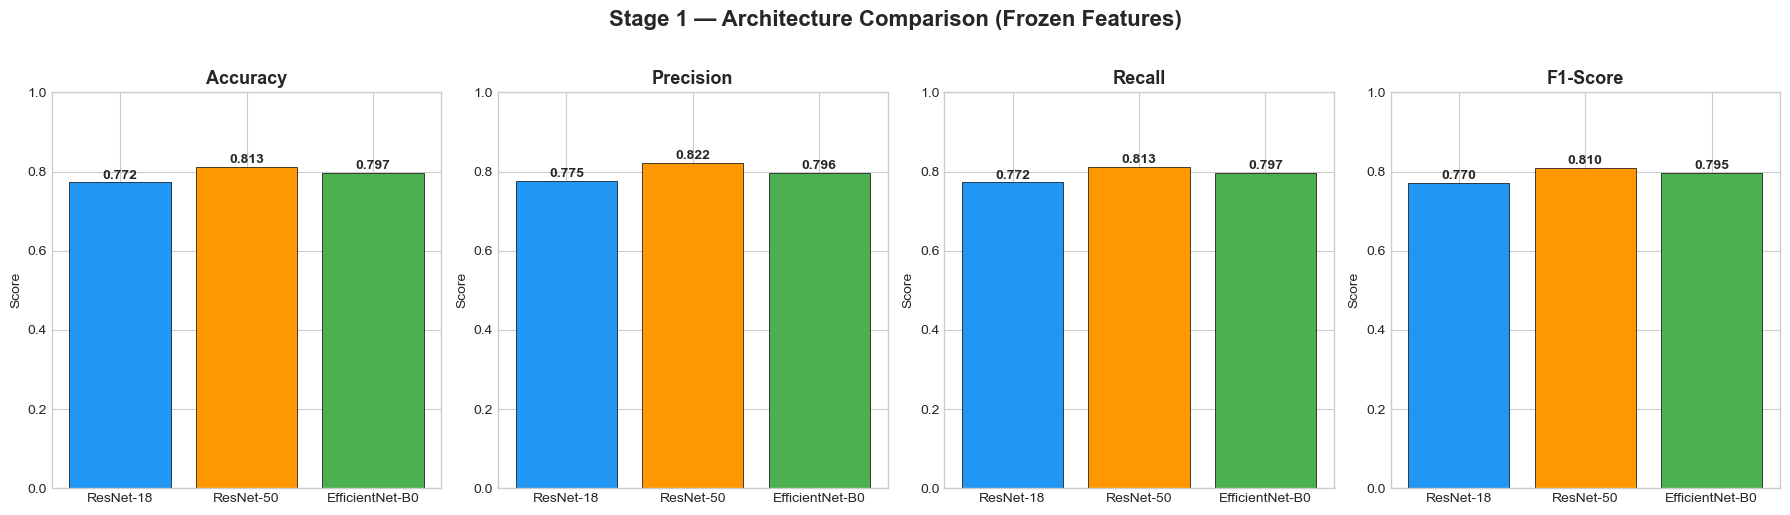

In [30]:
# Bar chart comparison
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
metrics_cols = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
colors = ['#2196F3', '#FF9800', '#4CAF50']
labels = ['ResNet-18', 'ResNet-50', 'EfficientNet-B0']

for i, metric in enumerate(metrics_cols):
    values = comparison_df[metric].values
    bars = axes[i].bar(labels, values, color=colors, edgecolor='black', linewidth=0.5)
    axes[i].set_title(metric, fontsize=13, fontweight='bold')
    axes[i].set_ylim(0, 1.0)
    axes[i].set_ylabel('Score')
    for bar, val in zip(bars, values):
        axes[i].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
                     f'{val:.3f}', ha='center', fontsize=10, fontweight='bold')

fig.suptitle('Stage 1 — Architecture Comparison (Frozen Features)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

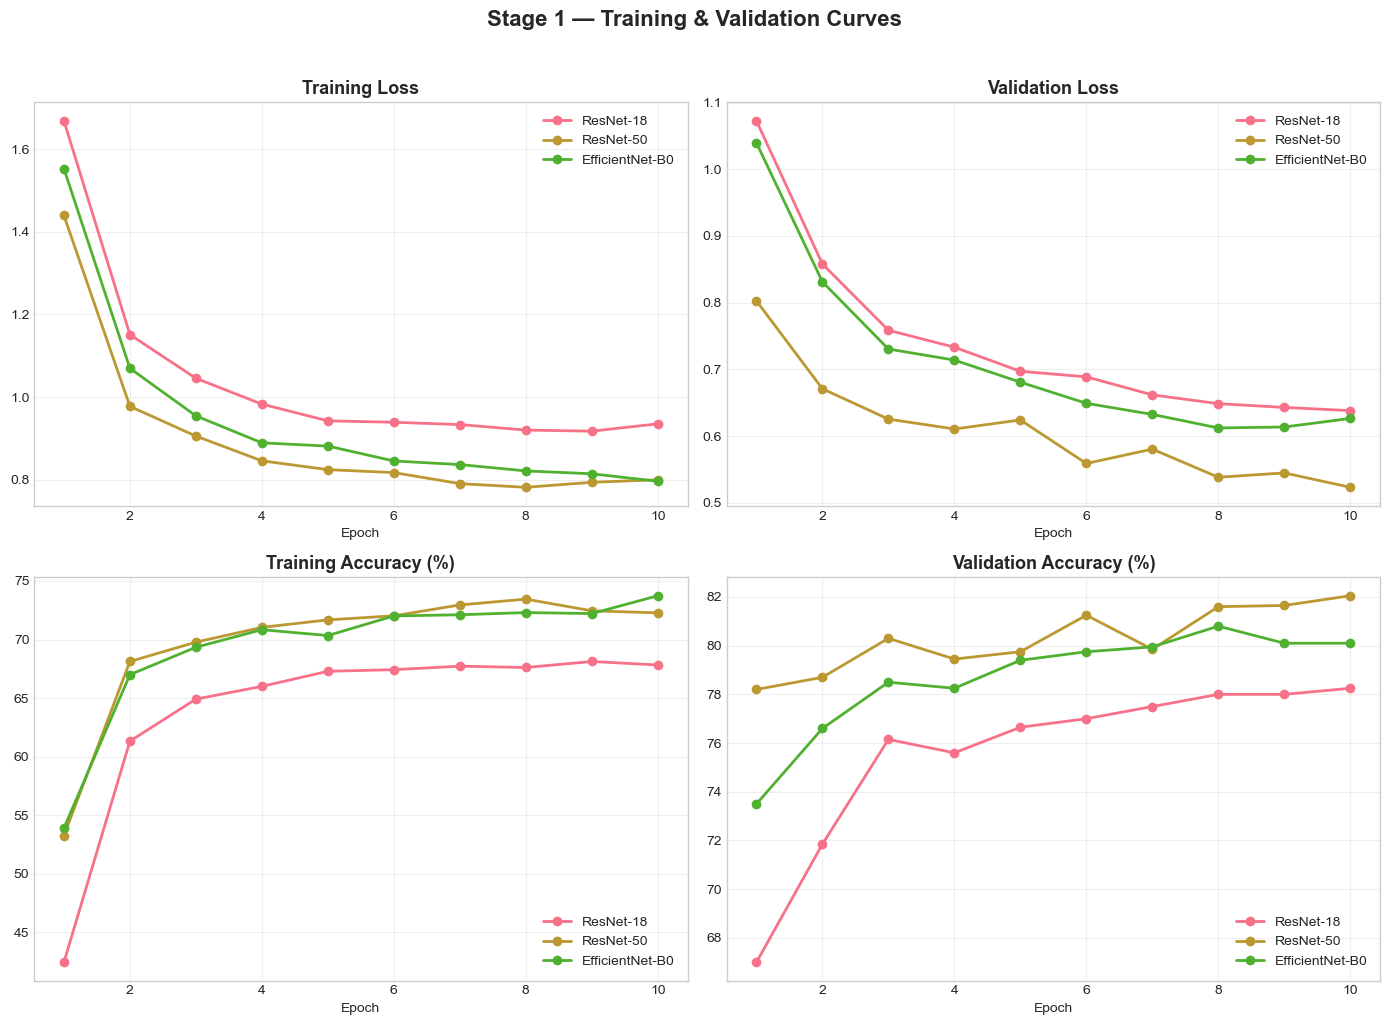

In [31]:
# Training and validation curves — all 3 models
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

all_hists = {'ResNet-18': resnet18_hist, 'ResNet-50': resnet50_hist, 'EfficientNet-B0': effnet_hist}

for name, h in all_hists.items():
    epochs = range(1, len(h['train_loss']) + 1)
    axes[0, 0].plot(epochs, h['train_loss'], marker='o', label=name, linewidth=2)
    axes[0, 1].plot(epochs, h['val_loss'], marker='o', label=name, linewidth=2)
    axes[1, 0].plot(epochs, h['train_acc'], marker='o', label=name, linewidth=2)
    axes[1, 1].plot(epochs, h['val_acc'], marker='o', label=name, linewidth=2)

titles = ['Training Loss', 'Validation Loss', 'Training Accuracy (%)', 'Validation Accuracy (%)']
for ax, title in zip(axes.flat, titles):
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel('Epoch'); ax.legend(); ax.grid(True, alpha=0.3)

fig.suptitle('Stage 1 — Training & Validation Curves', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

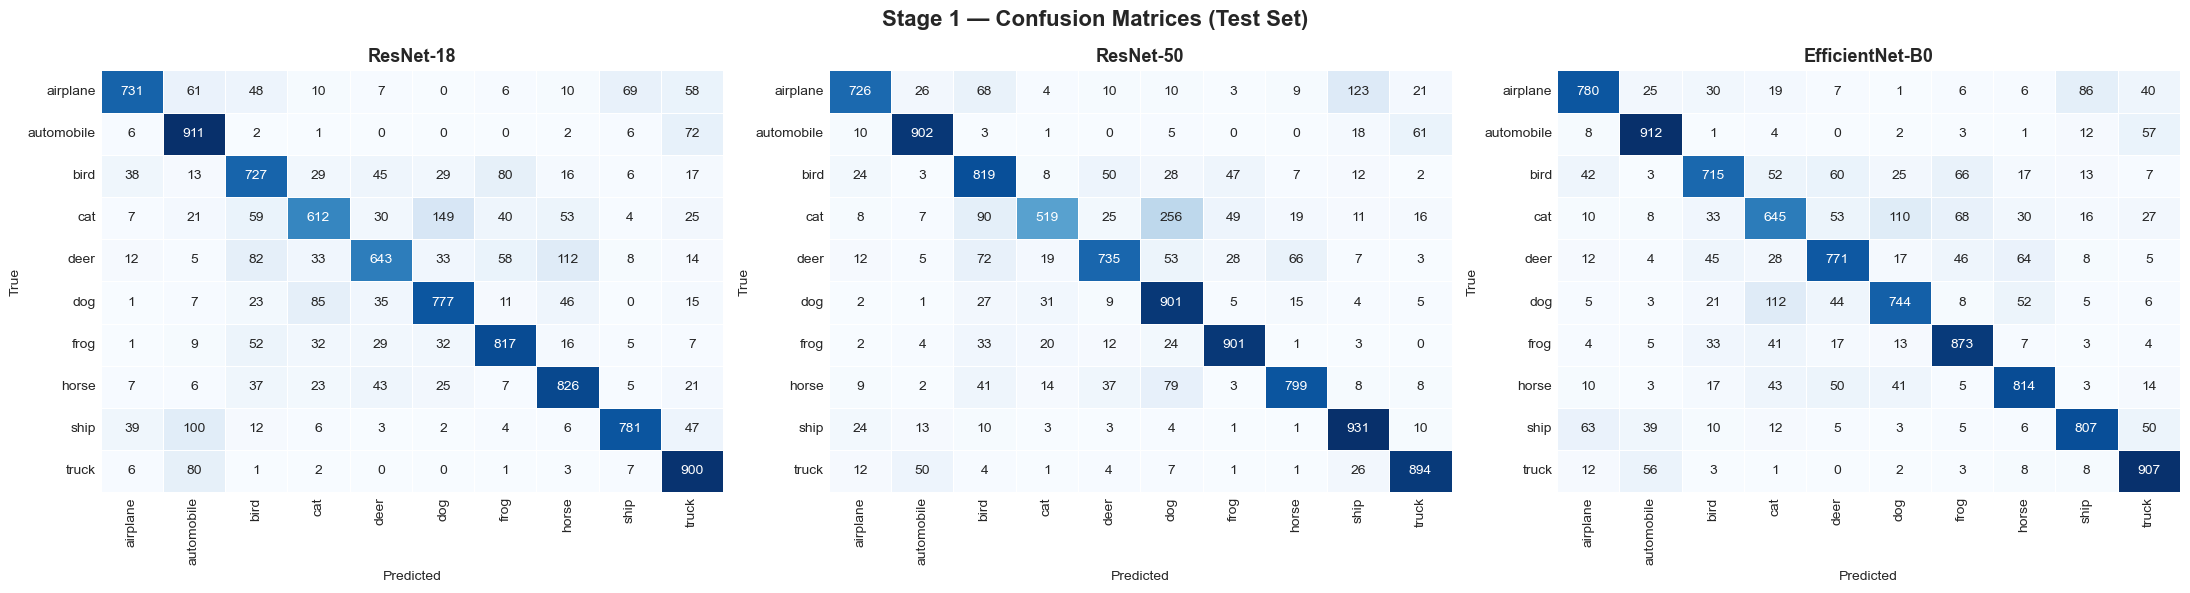

In [32]:
# Confusion matrices — side by side
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
all_preds_list = [resnet18_preds, resnet50_preds, effnet_preds]
names = ['ResNet-18', 'ResNet-50', 'EfficientNet-B0']

for i, (preds, name) in enumerate(zip(all_preds_list, names)):
    cm = confusion_matrix(test_labels, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES,
                yticklabels=CLASSES, ax=axes[i], linewidths=0.5, cbar=False)
    axes[i].set_title(name, fontsize=13, fontweight='bold')
    axes[i].set_xlabel('Predicted'); axes[i].set_ylabel('True')

fig.suptitle('Stage 1 — Confusion Matrices (Test Set)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [33]:
# Per-class classification reports
for name, preds in zip(names, all_preds_list):
    print(f"\n{'='*70}")
    print(f"  {name} — Per-Class Classification Report")
    print(f"{'='*70}")
    print(classification_report(test_labels, preds, target_names=CLASSES, digits=4))


  ResNet-18 — Per-Class Classification Report
              precision    recall  f1-score   support

    airplane     0.8620    0.7310    0.7911      1000
  automobile     0.7510    0.9110    0.8233      1000
        bird     0.6970    0.7270    0.7117      1000
         cat     0.7347    0.6120    0.6678      1000
        deer     0.7701    0.6430    0.7008      1000
         dog     0.7421    0.7770    0.7592      1000
        frog     0.7979    0.8170    0.8073      1000
       horse     0.7578    0.8260    0.7904      1000
        ship     0.8765    0.7810    0.8260      1000
       truck     0.7653    0.9000    0.8272      1000

    accuracy                         0.7725     10000
   macro avg     0.7754    0.7725    0.7705     10000
weighted avg     0.7754    0.7725    0.7705     10000


  ResNet-50 — Per-Class Classification Report
              precision    recall  f1-score   support

    airplane     0.8758    0.7260    0.7939      1000
  automobile     0.8904    0.9020    0